# Imports

In [1]:
import numpyro
numpyro.set_host_device_count(4)

import jax
import jax.numpy as jnp
import numpy as np
print("JAX:", jax.__version__)
print("local device count:", jax.local_device_count())
print("local devices:")
for d in jax.local_devices():
    print("  ", d)
    
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value

from likelihood import (
    FD_gaussianlikelihood,
    FD_marg_fullnormal_gaussianlikelihood,
    draw_fluences_fullnormal_gaussmarg,
    FD_marg_halfnormal_nooverlap_gaussianlikelihood,
    draw_fluences_halfnormal_nooverlap_gaussmarg,
    wraparound_ratio_posthoc,
)
from model import (
    setup_model,
    make_orthogonal_poly_sed
)

from data import(
    prepare_burst
)

from run import(
    set_priors,
    run_fit,
    posthoc_samples
)

from results import(
    save_run
)

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import arviz as az
import arviz_plots as azp
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import random

/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


JAX: 0.11.1
local device count: 4
local devices:
   cpu:0
   cpu:1
   cpu:2
   cpu:3


In [2]:
# import sys
# print(sys.executable)  # Should point to your venv path, not /mnt/sw/nix/...

In [3]:
# import tqdm.std

# # Force tqdm to use newlines and flush output instantly for Jupyter
# def line_printer(file):
#     def print_status(s):
#         file.write(s.replace("\r", "") + "\n")
#         file.flush()
#     return print_status

# tqdm.std.status_printer = line_printer

In [4]:
# import sys
# import tqdm.std

# class ThreadSafeStdOut:
#     def __init__(self, stream):
#         self.stream = stream
#     def write(self, s):
#         self.stream.write(s)
#         self.stream.flush()
#     def flush(self):
#         self.stream.flush()

# # Override tqdm's default output file handle
# tqdm.std.tqdm.stqdm_file = ThreadSafeStdOut(sys.stdout)

# Working with run.py

In [ ]:
from pathlib import Path

PROJECT  = Path("/mnt/home/hsiegel/FRBayes")
event_id = "22310619_BB"

data_path = PROJECT / "data" / f"event_{event_id}.npz"
out_path  = PROJECT / "runs" / f"event_{event_id}.nc"
out_path.parent.mkdir(parents=True, exist_ok=True)     # create runs/ if it doesn't exist

burst = prepare_burst(
    path=data_path,
    n_avg=16,                # frequency channels averaged per block
    fd_downsample=8,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

n_pulses = 3
priors = set_priors(burst, single_pulse_fn, s_opt=100.0)
mcmc   = run_fit(burst, single_pulse_fn, priors, FD_gaussianlikelihood, num_chains=4, n_pulses=n_pulses)
samples = mcmc.get_samples()
# extra = mcmc.get_extra_fields()
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})
# extra  = posthoc_samples(mcmc, burst, single_pulse_fn, priors)
# idata  = save_run(None, mcmc, burst, priors, data_path,
#                   single_pulse_fn=single_pulse_fn, extra_samples=extra, event_id=event_id)

806 good channels -> 50 blocks of 16 (6 dropped); block span median 6.641 MHz, max 37.109 MHz
noise estimated from 171 of 858 time bins (first 20% of the segment)
Fourier truncation: keeping 52 of 430 bins (up to 5.9 kHz of 48.8 kHz)
weighted mean frequency 592.4 MHz, reference frequency 563.1 MHz
prior being set with bounds:
sigma_min = 2.6890819453714833e-05 
sigma_max = 0.0014643199911006377 
tau_ref_min = 0.0 
tau_ref_max = 0.0011637152739660515
prior being set with bounds:
c1_min = -1.9209625 
c1_max = 38.41925 
c2_min = -5.0385747 
c2_max = 0.25192875
mean_arrival_time: Uniform(low=0, high=0.00877568)
DM: Uniform(low=-0.234355, high=0.234355)
sigma: Uniform(low=2.68908e-05, high=0.00146432)
tau_ref: Uniform(low=0, high=0.00116372)
c1: Uniform(low=-1.92096, high=38.4193)
c2: Uniform(low=-5.03857, high=0.251929)
A_snr: HalfNormal(scale=100)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling th

Compiling.. :   0%|          | 0/1200 [00:00<?, ?it/s]

  0%|          | 0/1200 [00:00<?, ?it/s]

Compiling.. :   0%|          | 0/1200 [00:00<?, ?it/s]


  0%|          | 0/1200 [00:00<?, ?it/s]


Compiling.. :   0%|          | 0/1200 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


In [6]:
# # -------------------------------------------------------------------
# # Plot the sampler's starting pulses against the data
# # -------------------------------------------------------------------
# # Uses `burst`, `priors` and `single_pulse_fn` from the cells above. Nothing is sampled: the
# # model is traced once with the starting values that run_fit would use, and the resulting
# # pulses are drawn over the data.
# #
# # The starting amplitudes are random draws, so for display each pulse is instead scaled by the
# # least-squares amplitude that best matches the data given its shape (clipped at zero). That
# # puts the pulses on the data's scale; it does not change where they start.
# #
# # Both data and model are shown on the retained Fourier bins only, i.e. low-passed exactly as
# # the likelihood sees them.

# import numpy as np
# import jax
# import jax.numpy as jnp
# import matplotlib.pyplot as plt
# import matplotlib.gridspec as gridspec
# import numpyro.distributions as dist
# from numpyro import handlers

# from run import default_init
# from likelihood import FD_gaussianlikelihood, matched_filter_and_gram
# from pathlib import Path


# PROJECT  = Path("/arc/home/hsiegel/FRBayes")
# # event_id = "22154974_BB"
# event_id = "22310619_BB"

# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# out_path  = PROJECT / "runs" / f"event_{event_id}.nc"
# out_path.parent.mkdir(parents=True, exist_ok=True)     # create runs/ if it doesn't exist

# burst = prepare_burst(
#     path=data_path,
#     n_avg=8,                # frequency channels averaged per block
#     fd_downsample=4,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# constants_dict = {
#     "freq_channels_ref": burst.freq_channels_ref,
#     "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
#     "channel_width": burst.channel_width,
# }

# single_pulse_fn = setup_model(
#     constants_dict=constants_dict,
#     freqs_channels=burst.freq_channels,
#     times=burst.times,
#     sed_fn=make_orthogonal_poly_sed(*burst.spectral_basis),
#     fourier_freqs=burst.fourier_freqs,
# )
# priors = set_priors(burst, single_pulse_fn, s_opt=100.0)

# n_pulses = 5
# # ---- 1. Starting values, read off one trace of the model ----
# # The starting point is the same for every likelihood, so the unmarginalized one is traced
# # here; it needs an amplitude prior, which is added for this trace only if absent.
# init = default_init(burst, priors, n_pulses)
# trace_priors = dict(priors)
# if not ({"A", "A_snr"} & trace_priors.keys()):
#     trace_priors["A_snr"] = dist.HalfNormal(100.0)
 
# model = handlers.substitute(handlers.seed(FD_gaussianlikelihood, 0), substitute_fn=init)
# trace = handlers.trace(model).get_trace(
#     data_fd=burst.data_fd,
#     sigma_noise_fd=burst.sigma_noise_fd,
#     n_pulses=n_pulses,
#     priors=trace_priors,
#     single_pulse_fn=single_pulse_fn,
#     spectral_coeff_map=burst.spectral_coeff_map if "c1" in priors else None,
# )
 
# shape_names = [k for k in ("mean_arrival_time", "sigma", "DM", "tau_ref", "c1", "c2",
#                            "gamma", "beta", "delta") if k in trace]
# start = {k: jnp.asarray(trace[k]["value"]).reshape(n_pulses) for k in shape_names}
 
# print("starting values:")
# for k, v in start.items():
#     print(f"  {k:18s} {np.round(np.asarray(v), 7)}")
 
# # ---- 2. Templates, all scaled to the same signal-to-noise ----
# # Every pulse gets the same optimal SNR, so each one is visible however it overlaps the data or
# # its neighbours. (A least-squares fit to the data is NOT used here: overlapping starting
# # templates trade amplitude, and several come out negative and vanish from the plot.)
# templates = jax.vmap(single_pulse_fn)(start)                     # (P, nfreq, nfourier), unit fluence
# inv_noise_var = 1.0 / jnp.broadcast_to(jnp.asarray(burst.sigma_noise_fd), burst.data_fd.shape) ** 2
# rho, gram = matched_filter_and_gram(templates, burst.data_fd, inv_noise_var)
# snr_opt = jnp.sqrt(jnp.diag(gram))
# A_display = 1.0 / snr_opt                                        # unit SNR each; rescaled to the data below
 
# # ---- 3. Back to the time domain, on the retained Fourier bins ----
# # Each retained bin goes back to its own index on the full rfft grid before inverting, so the
# # truncation and the dropped DC bin are respected.
# n_full = burst.n_time // 2 + 1
# df = 1.0 / (burst.n_time * burst.dt)
# bin_index = np.rint(np.asarray(burst.fourier_freqs).reshape(-1) / df).astype(int)
 
# def to_time_domain(X):
#     X = np.asarray(X)
#     full = np.zeros(X.shape[:-1] + (n_full,), dtype=complex)
#     full[..., bin_index] = X
#     return np.fft.irfft(full, n=burst.n_time, axis=-1) / burst.dt
 
# data_td = to_time_domain(burst.data_fd)                                       # (nfreq, ntime)
# pulses_td = to_time_domain(np.asarray(A_display)[:, None, None] * np.asarray(templates))  # (P, nfreq, ntime)
 
# # One overall factor so the summed starting model peaks at the data's peak, for comparison
# scale = data_td.sum(axis=0).max() / pulses_td.sum(axis=(0, 1)).max()
# pulses_td = scale * pulses_td
# model_td = pulses_td.sum(axis=0)
# resid_td = data_td - model_td
 
# times = np.asarray(burst.times).reshape(-1)
# freq = np.asarray(burst.freq_channels).reshape(-1)
# t0 = np.asarray(start["mean_arrival_time"])
# sig = np.asarray(start["sigma"])
 
# # ---- 4. Plot ----
# fig = plt.figure(figsize=(13, 7))
# gs = gridspec.GridSpec(2, 3, height_ratios=[1.3, 3], hspace=0.08, wspace=0.08, figure=fig)
 
# ax_ts = fig.add_subplot(gs[0, :])
# ax_d = fig.add_subplot(gs[1, 0])
# ax_m = fig.add_subplot(gs[1, 1], sharex=ax_d, sharey=ax_d)
# ax_r = fig.add_subplot(gs[1, 2], sharex=ax_d, sharey=ax_d)
 
# # Top: frequency-summed time series
# colors = plt.cm.tab10(np.arange(n_pulses) % 10)
# ax_ts.plot(times, data_td.sum(axis=0), color="0.6", lw=0.8, label="data")
# ax_ts.plot(times, model_td.sum(axis=0), color="k", lw=1.5, label="starting model (sum)")
# for j in range(n_pulses):
#     ax_ts.plot(times, pulses_td[j].sum(axis=0), color=colors[j], lw=1.2, ls="--",
#                label=f"pulse {j}: t0={t0[j]*1e3:.3f} ms, sigma={sig[j]*1e3:.3f} ms")
#     ax_ts.axvline(t0[j], color=colors[j], lw=0.8, alpha=0.6)
# ax_ts.set_xlim(times[0], times[-1])
# ax_ts.set_ylabel("summed over freq")
# ax_ts.legend(fontsize=8, loc="upper right")
# ax_ts.set_title(f"Starting point for n_pulses = {n_pulses} (equal SNR per pulse, for display)")
# ax_ts.tick_params(labelbottom=False)
 
# # Bottom: waterfalls
# extent = (times[0], times[-1], freq[0], freq[-1])
# vmin, vmax = np.percentile(data_td, [1, 99])
# vres = np.percentile(np.abs(resid_td), 99)
# kw = dict(aspect="auto", origin="lower", interpolation="nearest", extent=extent)
# ax_d.imshow(data_td, cmap="viridis", vmin=vmin, vmax=vmax, **kw)
# ax_m.imshow(model_td, cmap="viridis", vmin=vmin, vmax=vmax, **kw)
# ax_r.imshow(resid_td, cmap="RdBu_r", vmin=-vres, vmax=vres, **kw)
# for ax, title in ((ax_d, "data"), (ax_m, "starting model"), (ax_r, "residual")):
#     ax.set_title(title, fontsize=10)
#     ax.set_xlabel("time [s]")
#     for j in range(n_pulses):
#         ax.axvline(t0[j], color=colors[j], lw=0.6, alpha=0.5)
# ax_d.set_ylabel("frequency [MHz]")
# ax_m.tick_params(labelleft=False)
# ax_r.tick_params(labelleft=False)
 
# plt.show()


In [7]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.000,0.000,0.000,0.000,938.221,591.564,1.003,0.000,0.000
A[1],0.000,0.000,0.000,0.000,950.561,535.807,1.007,0.000,0.000
A_snr[0],43.779,1.050,42.109,45.474,1043.709,591.662,1.001,0.033,0.030
A_snr[1],58.822,0.990,57.246,60.434,994.412,701.700,1.007,0.031,0.031
DM[0],-0.003,0.001,-0.004,-0.002,953.010,569.921,1.009,0.000,0.000
DM[1],-0.003,0.001,-0.004,-0.002,953.010,569.921,1.009,0.000,0.000
DM_shared,-0.003,0.001,-0.004,-0.002,953.010,569.921,1.009,0.000,0.000
beta[0],1.842,0.669,0.755,2.886,1124.805,577.822,1.019,0.020,0.028
beta[1],-9.048,1.465,-11.650,-6.968,987.868,546.361,1.001,0.049,0.055
c1[0],-0.636,0.026,-0.680,-0.592,1064.000,548.140,1.001,0.001,0.001


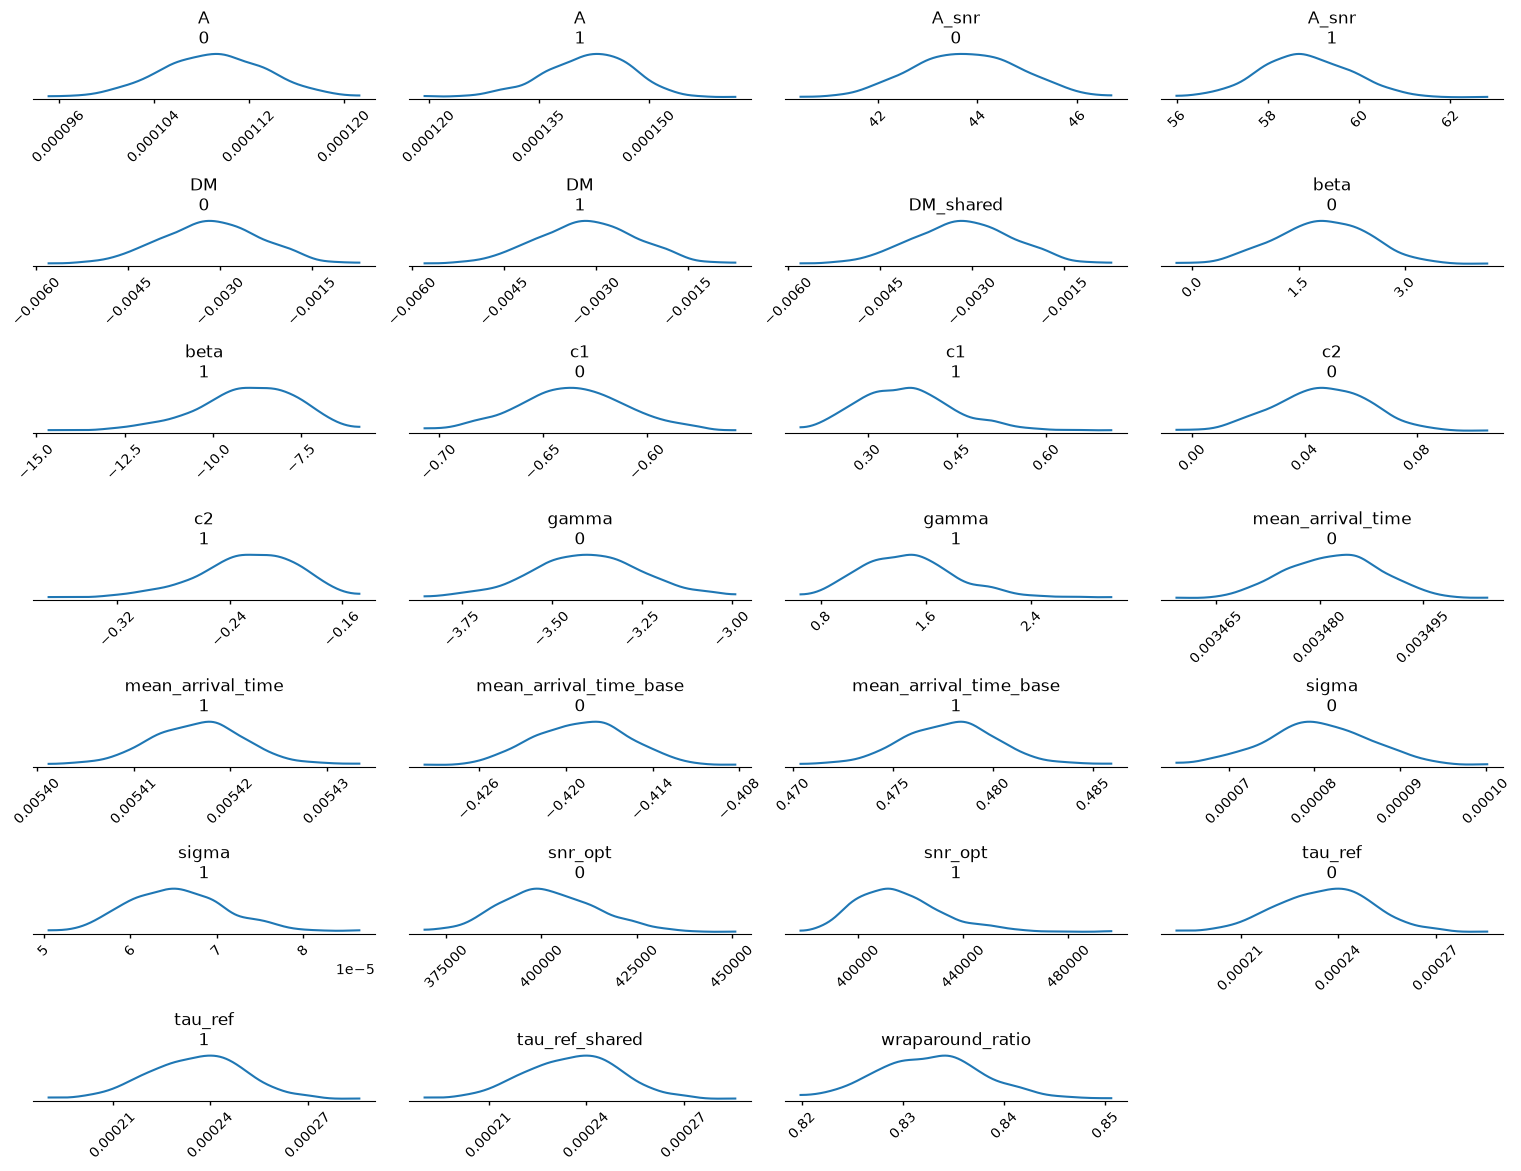

In [8]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw() 

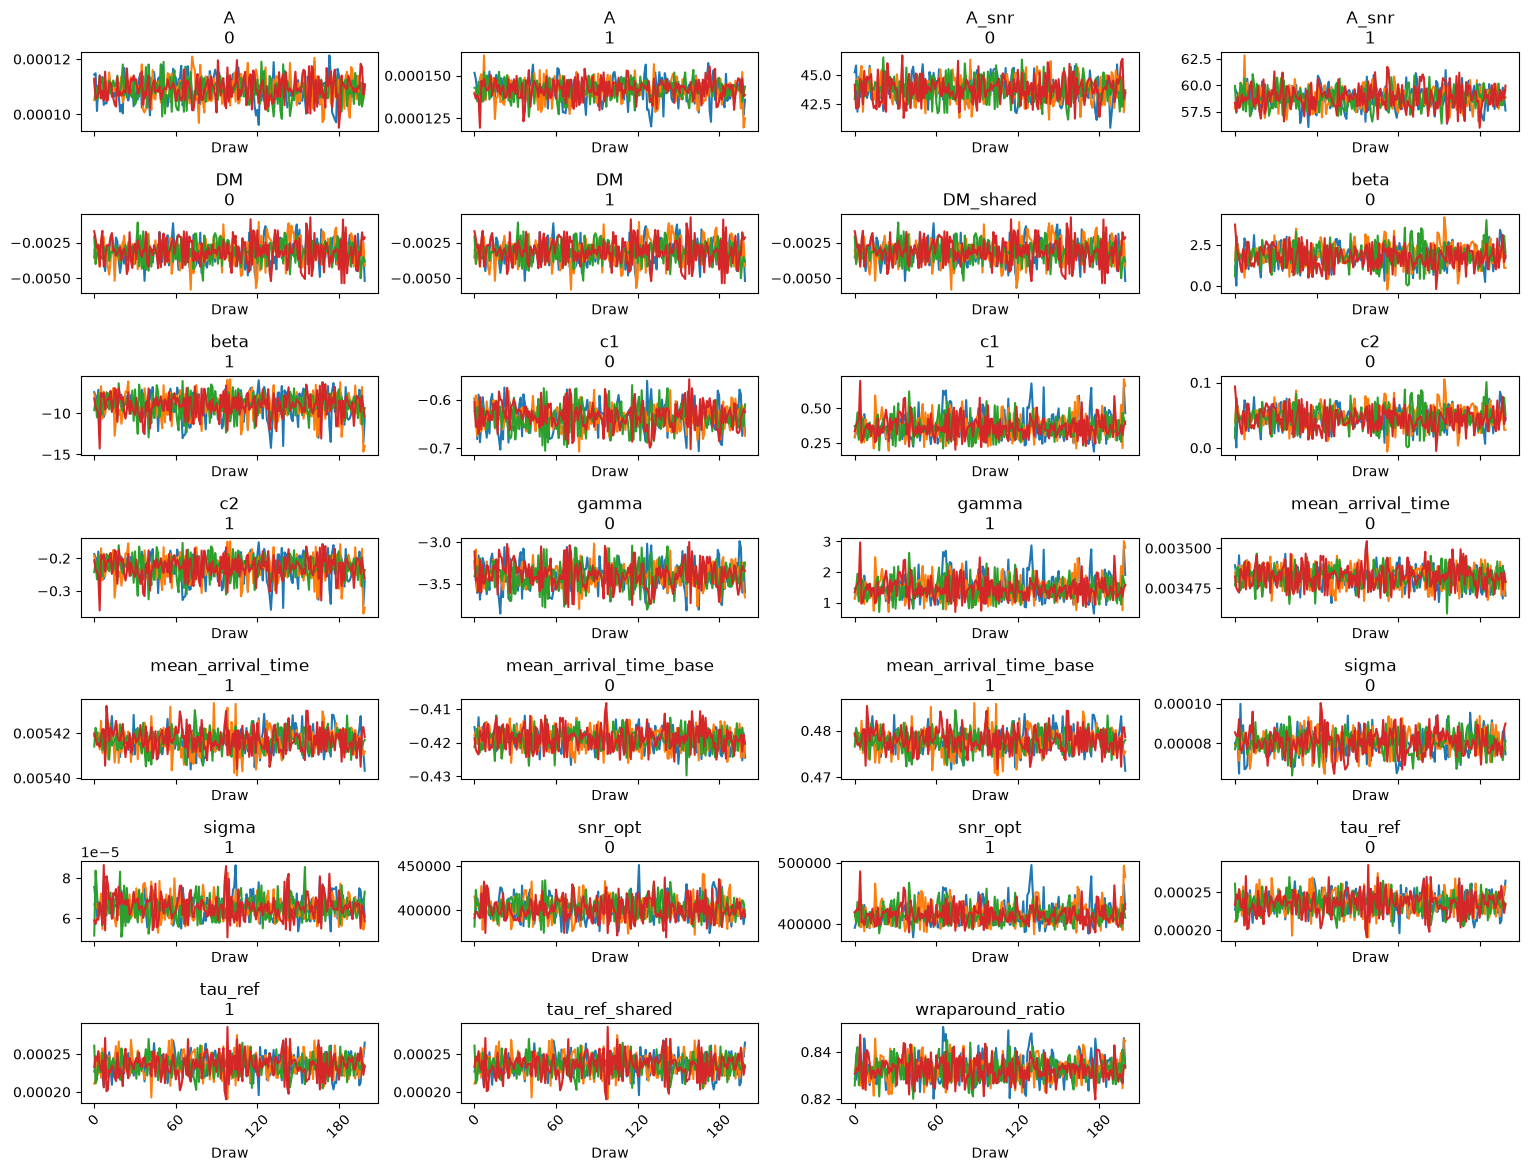

In [10]:
azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Plotting for Posterior Draw #796, 2 pulse(s)


/tmp/ipykernel_4125054/2122320383.py:129: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


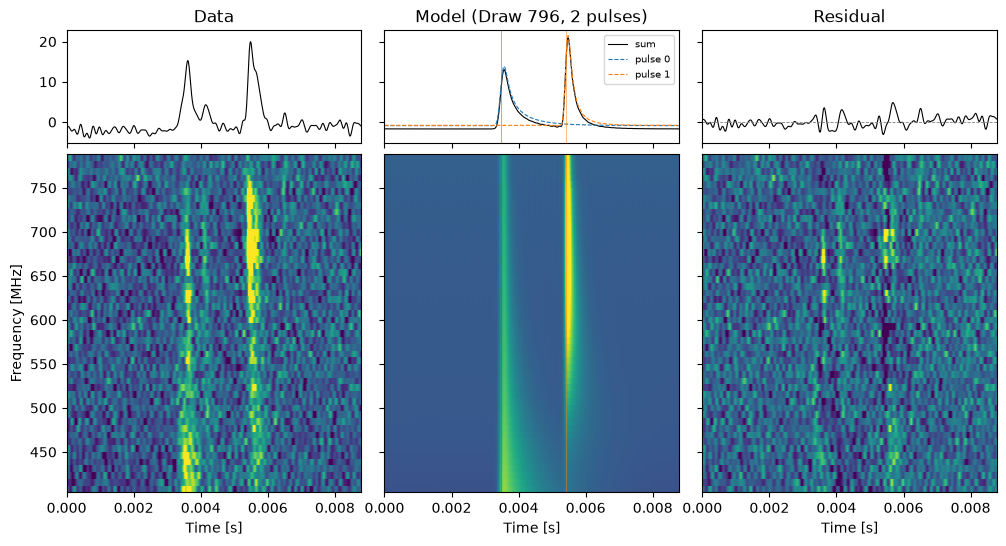

In [11]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Evaluate Forward Model
# -------------------------------------------------------------------
# samples = dict(mcmc.get_samples())
# For a marginalized fit, the fluences are not sampled: add the post-hoc draws first, flattened
# to (draws, n_pulses) to match get_samples(), e.g.
#     samples["A"] = extra["A"].reshape(-1, extra["A"].shape[-1])
if "A" not in samples:
    raise KeyError("samples has no 'A'. For a marginalized fit, add the fluences drawn by "
                   "posthoc_samples first (see the comment above).")

num_draws = len(next(iter(samples.values())))
n_pulses = samples["mean_arrival_time"].shape[-1]

# Pick a draw index using JAX random
key = jax.random.PRNGKey(1)
draw_idx = int(jax.random.randint(key, shape=(), minval=0, maxval=num_draws))
print(f"Plotting for Posterior Draw #{draw_idx}, {n_pulses} pulse(s)")

# Parameters of the chosen draw, each an array of shape (n_pulses,). Only the parameters the
# model reads are taken; 'A' is the fluence, which single_pulse_fn applies itself.
param_names = [k for k in ("mean_arrival_time", "sigma", "DM", "tau_ref", "c1", "c2",
                           "gamma", "beta", "delta", "A") if k in samples]
test_params = {k: jnp.asarray(samples[k][draw_idx]).reshape(n_pulses) for k in param_names}

# Evaluate every pulse (vmap over the pulse axis), then sum them for the full model
M_FD_pulses = jax.vmap(single_pulse_fn)(test_params)       # (n_pulses, nfreq, nfourier)
M_FD = jnp.sum(M_FD_pulses, axis=0)                        # (nfreq, nfourier)

# The data and model live on the retained Fourier bins only, so each bin is put back at its own
# index on the full rfft grid before inverting; irfft on the truncated array would reinterpret
# bin k as frequency k / (Nseg dt), which is not where it came from.
Nseg = burst.n_time
dt = burst.dt
n_full = Nseg // 2 + 1
bin_index = jnp.rint(jnp.asarray(burst.fourier_freqs).reshape(-1) * Nseg * dt).astype(int)
pad = lambda X: jnp.zeros(X.shape[:-1] + (n_full,), X.dtype).at[..., bin_index].set(X)

to_TD = lambda X: (1.0 / dt) * jnp.fft.irfft(pad(X), n=Nseg, axis=-1)
M_TD = to_TD(M_FD)
M_TD_pulses = to_TD(M_FD_pulses)                           # (n_pulses, nfreq, ntime)
data_TD = to_TD(burst.data_fd)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = burst.times
freq_plot = jnp.squeeze(burst.freq_channels)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
pulse_ts = jnp.nansum(M_TD_pulses, axis=1)                 # (n_pulses, ntime)
resid_ts = data_ts - model_ts

# Shared robust color limits using jnp
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8, label="sum")
if n_pulses > 1:
    # Each component separately, and its arrival time (at the reference frequency)
    colors = plt.cm.tab10(np.arange(n_pulses) % 10)
    t0 = np.asarray(test_params["mean_arrival_time"])
    for j in range(n_pulses):
        ax_ts_model.plot(time_plot, pulse_ts[j], color=colors[j], lw=0.8, ls="--", label=f"pulse {j}")
        for ax in (ax_ts_model, ax_wf_model):
            ax.axvline(t0[j], color=colors[j], lw=0.6, alpha=0.6)
    ax_ts_model.legend(fontsize=7, loc="upper right")
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title(f"Model (Draw {draw_idx}, {n_pulses} pulse{'s' if n_pulses > 1 else ''})")
ax_ts_resid.set_title("Residual")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

Max Data abs : 8.283221
Max Model abs: 5.9786963
whitened residual sd: 1.115  (expect 1)


/tmp/ipykernel_4058978/3866287201.py:106: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


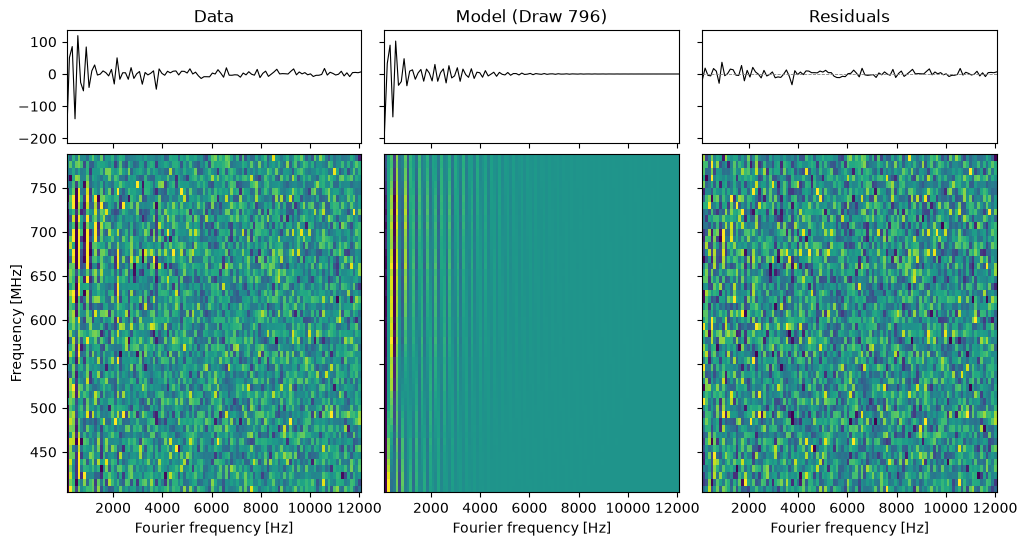

In [20]:
# -------------------------------------------------------------------
# 1. Forward model evaluation, Fourier domain
# -------------------------------------------------------------------
# test_params comes from the posterior-draw cell: each entry has shape (n_pulses,). Every pulse
# is evaluated (vmap over the pulse axis) and the pulses are summed into the full model.
M_FD = jnp.sum(jax.vmap(single_pulse_fn)(test_params), axis=0)     # (nfreq, nfourier)

# The data and the model already live on the truncated Fourier axis, which is exactly the set
# of bins the likelihood uses, so nothing needs slicing here.
data_reshaped_FFT = burst.data_fd
sigma_bins = jnp.broadcast_to(burst.sigma_noise_fd, data_reshaped_FFT.shape)

# Whitened, so all three panels are in units of sigma and the residual should be N(0, 1) noise
data_FD_plot = (data_reshaped_FFT / sigma_bins).real
model_FD_plot = (M_FD / sigma_bins).real
resid_FD_plot = data_FD_plot - model_FD_plot

fourier_freqs = burst.fourier_freqs
fourier_plot = jnp.asarray(fourier_freqs).reshape(-1)
freq_plot = jnp.squeeze(burst.freq_channels)

print("Max Data abs :", jnp.max(jnp.abs(data_FD_plot)))
print("Max Model abs:", jnp.max(jnp.abs(model_FD_plot)))
print(f"whitened residual sd: {float(jnp.std(resid_FD_plot)):.3f}  (expect 1)")

# -------------------------------------------------------------------
# 2. Channel-summed spectra
# -------------------------------------------------------------------
data_ts = jnp.nansum(data_FD_plot, axis=0)
model_ts = jnp.nansum(model_FD_plot, axis=0)
resid_ts = data_ts - model_ts

# Data & Model limits
vmin, vmax = jnp.nanpercentile(data_FD_plot, jnp.array([1.0, 99.0]))

# Independent zero-centered limits for Residuals
vmax_res = jnp.nanpercentile(jnp.abs(resid_FD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: channel-summed spectra ---
ax_ts_data.plot(fourier_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(fourier_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(fourier_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_FD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_FD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_FD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_data.set_title("Data")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Fourier frequency [Hz]")
ax_wf_model.set_xlabel("Fourier frequency [Hz]")
ax_wf_resid.set_xlabel("Fourier frequency [Hz]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

# Consolidating all code

## Setting Priors

In [5]:
def width_prior_bounds(burst, toa, n_efold_tau=1.0, n_sigma_stds = 3, nu_bot=None, scattering_index=-4.0):
    """
    Loose box bounds for the width and scattering timescale, as entries for the priors dict.

    These are deliberately weak: each parameter alone, at its bound, just fits inside the segment,
    and nothing stops a draw where both are large at once. The joint condition is left to
    `sample_contained_lowestFDbin`, which acts on the evaluated model and so sees the combination.
    The box only prevents the sampler wandering somewhere absurd.

    sigma is bounded so that n_efold widths fit between the arrival time and whichever segment
    edge is closer, since a Gaussian is symmetric. Its floor is the narrowest resolvable width,
    1 / (2 pi f_max) from the Fourier truncation: below that the template has not rolled off
    within the retained bins, so the data do not constrain it. (The sampling interval is not the
    relevant floor -- without truncation the resolvable width would be dt / pi, below dt itself.)

    tau is bounded at the BOTTOM of the band, where the tail is longest, by requiring n_efold
    e-folds between the arrival time and the end of the segment, then converted to tau_ref.

    toa:      arrival time (s, relative to the segment start)
    n_efold_tau:  how many widths or e-folds must fit of the scattering transfer function parameter tau
    n_sigma_stds: how many standard deviations must fit of the pulse width parameter sigma
    nu_bot:   bottom of the band (MHz); taken from the burst's lowest channel if None
    """
    W = burst.n_time * burst.dt
    f_max = float(burst.fourier_freqs[-1])
    nu_bot = float(burst.freq_channels[0][0]) if nu_bot is None else nu_bot

    sigma_min = 1.0 / (2.0 * np.pi * f_max)
    sigma_max = min(toa, W - toa) / n_sigma_stds

    tau_ref_min = 0.0
    tau_bot_max = (W - toa) / n_efold_tau
    tau_ref_max = tau_bot_max * (nu_bot / burst.freq_channels_ref) ** (-scattering_index)

    if not sigma_min < sigma_max:
        raise ValueError(
            f"no width is both resolvable ({sigma_min:.2e} s) and containable ({sigma_max:.2e} s); "
            f"the segment is too short or the Fourier truncation too aggressive."
        )
    print("prior being set with bounds:\nsigma_min =",sigma_min,"\nsigma_max =",
          sigma_max,"\ntau_ref_min =",tau_ref_min,"\ntau_ref_max =",tau_ref_max)
    
    return {
        "sigma_min": sigma_min,
        "sigma_max": sigma_max,
        "tau_ref_min": tau_ref_min,
        "tau_ref_max": tau_ref_max,
    }

In [6]:
def spectral_coeff_bounds(spectral_coeff_map, gamma_range, beta_range):
    """
    Bounds on the sampled c1, c2 of the SED corresponding to a box in the conventional gamma, beta.

    The map is linear, so a box in (gamma, beta) becomes a parallelogram in (c1, c2); this
    returns its bounding box, which is the tightest region expressible as independent uniform
    priors. That admits a little more than intended -- about 8% of the box falls outside the
    gamma-beta limits for a typical basis -- which is harmless when the limits are loose
    catalogue-wide bounds rather than informative constraints.

    Because the map is linear with constant Jacobian, a flat prior on (c1, c2) is also flat on
    (gamma, beta); no correcting factor is needed.
    """
    a1 = spectral_coeff_map["gamma_c1"]
    b2 = spectral_coeff_map["gamma_c2"]
    a2 = spectral_coeff_map["beta_c2"]

    corners = [((g - b2 * (b / a2)) / a1, b / a2) for g in gamma_range for b in beta_range]
    c1s, c2s = zip(*corners)
    
    print("prior being set with bounds:\nc1_min =",min(c1s),"\nc1_max =",
          max(c1s),"\nc2_min =",min(c2s),"\nc2_max =",max(c2s))


    return {
        "c1_min": min(c1s),
        "c1_max": max(c1s),
        "c2_min": min(c2s),
        "c2_max": max(c2s),
    }

In [7]:
def dispersion_prior_bounds(burst, single_pulse_fn):
    """
    Bounds for the residual dispersion measure, as an entry for the priors dict.

    Symmetric about zero, with the magnitude set so that a burst arriving in the middle of the
    segment at the top of the band would sweep to a segment edge by the bottom of the band:

        D_max = W_seg / [ 2 k_D ( nu_bot^epsilon - nu_top^epsilon ) ]

    Beyond that the sweep runs off the end of the segment, which the periodic Fourier-domain
    model would wrap around. The bound is loose in the sense that it ignores the pulse's own
    width and scattering, which also consume the segment; those are bounded separately by
    `width_prior_bounds`, and the joint case is left to the containment penalty.

    The data are assumed already dedispersed, so this is a residual about zero rather than an
    absolute DM; the symmetric range reflects that the residual may be of either sign.

    burst:           the ConditionedData, for the segment length and the band edges
    single_pulse_fn: the model closure, whose `.constants` supply k_DM and epsilon, so the prior
                     and the model cannot disagree about the dispersion law

    Returns {"DM": (lo, hi)}.
    """
    constants = single_pulse_fn.constants

    W_seg = burst.n_time * burst.dt
    nu_bot = float(burst.freq_channels.min())
    nu_top = float(burst.freq_channels.max())

    # Delay difference across the band per unit DM; positive since epsilon is negative
    sweep_per_DM = constants.k_DM * (nu_bot ** constants.epsilon - nu_top ** constants.epsilon)
    D_max = W_seg / (2.0 * sweep_per_DM)

    return {"DM": (-D_max, D_max)}

## Marginalized half normal orthog SED

In [8]:
# -------------------------------------------------------------------
# 1. Data Conditioning
# -------------------------------------------------------------------
# prepare_burst averages the frequency channels, transforms to the Fourier domain, truncates the
# Fourier axis, and builds the orthogonal spectral basis. Everything the model and likelihood
# need comes back in `burst`, so neither has to know how the conditioning was done.
burst = prepare_burst(
    path="/mnt/home/hsiegel/FRBayes/data/event_22154974_BB.npz",
    n_avg=8,                # frequency channels averaged per block
    fd_downsample=4,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

# -------------------------------------------------------------------
# 2. Model Closure Setup
# -------------------------------------------------------------------
constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
}

# Orthogonal spectral basis: sample c1, c2 rather than gamma, beta. Over a factor-of-two band
# x = ln(nu/nu_r) and x^2 are nearly parallel, which makes gamma and beta strongly degenerate;
# P1 and P2 are orthogonal in the metric set by the per-channel weights, and orthogonal to the
# constant, which also decouples them from the fluence.
#
# setup_model also builds the same model on [f1/2, f1], f1 = 1 / W_seg, and attaches it as
# single_pulse_fn.lowfreq_diagnostic, for the wraparound ratio. No separate closure is needed.
single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

# containment = dict(
#     n_sigma= 3.0,
#     n_tau = 1.0,
#     extent_max=0.5 * burst.n_time * burst.dt,                        # xi = 0.5, shared with D_max
#     sigma_min=1.0 / (2 * jnp.pi * float(burst.fourier_freqs[-1])),    # narrowest resolvable width
#     bot_over_ref=float(burst.freq_channels[0][0]) / burst.freq_channels_ref,
# )

# Wraparound penalty during sampling. None: nothing wraparound-related is computed while
# sampling, and the exact ratio is computed afterwards in section 4. To switch the penalty on,
# use the dict below; the ratio used during sampling is then recorded as
# 'wraparound_ratio_realtime_approx'.
containment_FD = None
# containment_FD = dict(
#     ratio_min=0.9,   # how much of the envelope must survive at f1
#     K=100.0,         # penalty at ratio = 0, in nats
#     w=0.01,          # sharpness of the transition
# )


# -------------------------------------------------------------------
# 3. Priors & NUTS Sampling
# -------------------------------------------------------------------

width_prior = width_prior_bounds(burst, toa=1.15e-3)
spectral_prior = spectral_coeff_bounds(burst.spectral_coeff_map, [-10,200],[-200,10])
DM_prior = dispersion_prior_bounds(burst,single_pulse_fn)
s_opt = 100


# priors = {
#     "mean_arrival_time": dist.Uniform(0.00115 - 2e-4, 0.00115 + 2e-4),   # (s, relative to segment start)

#     "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
#     "DM": dist.Uniform(-0.1, 0.1),                  # residual DM (pc cm^-3)
#     "tau_ref": dist.Uniform(1e-5, 2e-3),            # scattering timescale at nu_r (s)

#     # Orthogonal basis coefficients, O(1) by construction (unit weighted RMS basis). These are
#     # specific to this burst's basis and are not comparable between bursts; gamma and beta are
#     # recorded as deterministic sites via spectral_coeff_map and are what should be reported.
#     "c1": dist.Uniform(-3.0, 3.0),                  # linear basis coefficient
#     "c2": dist.Uniform(-3.0, 3.0),                  # quadratic basis coefficient
# }
priors = {
    "mean_arrival_time": dist.Uniform(0, burst.times[-1]),  # (s, relative to segment start)
    # "mean_arrival_time": dist.Uniform(0.00115 - 5*2e-4, 0.00115 + 7*2e-4),   # (s, relative to segment start)

    # "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
    "DM": dist.Uniform(-0.0864, 0.0864),                  # residual DM (pc cm^-3)
    # "tau_ref": dist.Uniform(1e-5, 2e-3),            # scattering timescale at nu_r (s)

    # Orthogonal basis coefficients, O(1) by construction (unit weighted RMS basis). These are
    # specific to this burst's basis and are not comparable between bursts; gamma and beta are
    # recorded as deterministic sites via spectral_coeff_map and are what should be reported.
    "c1": dist.Uniform(-3.0, 3.0),                  # linear basis coefficient
    "c2": dist.Uniform(-3.0, 3.0),                  # quadratic basis coefficient
    "sigma": dist.Uniform(width_prior["sigma_min"],width_prior["sigma_max"]),   # floor from the Fourier truncation
    "tau_ref": dist.Uniform(width_prior["tau_ref_min"],width_prior["tau_ref_max"]),
}
n_pulses = 1
s_opt = 100.0

num_warmup = 1000
num_samples = 200
num_chains = 1

kernel = NUTS(FD_marg_halfnormal_nooverlap_gaussianlikelihood, dense_mass=True)
mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains,
            chain_method="parallel")

# Fixed master key seed for reproducible sampling across runs
key_sampler, key_fluences = jax.random.split(jax.random.PRNGKey(7))

mcmc.run(
    key_sampler,
    data_fd=burst.data_fd,
    sigma_noise_fd=burst.sigma_noise_fd,
    n_pulses=n_pulses,
    priors=priors,
    single_pulse_fn=single_pulse_fn,
    s_opt=s_opt,
    spectral_coeff_map=burst.spectral_coeff_map,
    containment=None,
    containment_FD=containment_FD,
    extra_fields=("num_steps", "accept_prob", "diverging", "potential_energy")
)

# -------------------------------------------------------------------
# 4. Extract Posteriors, Recover Fluences, and Compute the Wraparound Ratio
# -------------------------------------------------------------------
samples = dict(mcmc.get_samples())
extra = mcmc.get_extra_fields()

# The half-normal marginalization integrates the fluences out, so they are drawn afterwards from
# their exact conditional: a normal truncated to A > 0, independent across components under the
# non-overlap assumption. Positivity is built into the prior, so every draw is valid.
samples["A"] = draw_fluences_halfnormal_nooverlap_gaussmarg(
    samples["snr_opt"], samples["snr_mf"], s_opt, key_fluences
)

# Exact wraparound ratio for every draw, from the fluences just drawn. Uses the same
# single_pulse_fn.lowfreq_diagnostic and noise weighting as the in-model version.
samples["wraparound_ratio"] = wraparound_ratio_posthoc(
    samples, samples["A"], single_pulse_fn, 1.0 / burst.sigma_noise_fd ** 2
)
print(f"wraparound_ratio: min {float(samples['wraparound_ratio'].min()):.4f}, "
      f"median {float(jnp.median(samples['wraparound_ratio'])):.4f}")

mcmc_data = az.from_dict(
    {"posterior": {k: np.asarray(v)[None, ...] for k, v in samples.items()}}
)

820 good channels -> 102 blocks of 8 (4 dropped); block span median 3.125 MHz, max 4.688 MHz
noise estimated from 65 of 329 time bins (first 20% of the segment)
Fourier truncation: keeping 40 of 165 bins (up to 11.9 kHz of 48.7 kHz)
weighted mean frequency 460.7 MHz, reference frequency 453.2 MHz
prior being set with bounds:
sigma_min = 1.3404665608610986e-05 
sigma_max = 0.00038333333333333334 
tau_ref_min = 0.0 
tau_ref_max = 0.0013766223072632156
prior being set with bounds:
c1_min = -5.25784 
c1_max = 21.606956 
c2_min = -3.6313496 
c2_max = 0.18156748


sample: 100%|██████████| 1200/1200 [00:04<00:00, 247.32it/s, 7 steps of size 3.79e-01. acc. prob=0.93]


wraparound_ratio: min 0.8465, median 0.8536


In [10]:
# -------------------------------------------------------------------
# 4. Extract Posteriors
# -------------------------------------------------------------------
samples = mcmc.get_samples()
extra = mcmc.get_extra_fields()
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

In [11]:
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

In [12]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
DM[0],-7.000000e-03,0.000000e+00,-7.000000e-03,-7.000000e-03,153.418,129.280,NaN,0.000000e+00,0.000000e+00
beta[0],-1.425800e+01,7.290000e-01,-1.536800e+01,-1.311400e+01,192.883,123.101,NaN,5.400000e-02,6.900000e-02
c1[0],-8.520000e-01,1.400000e-02,-8.750000e-01,-8.310000e-01,238.226,92.053,NaN,1.000000e-03,1.000000e-03
c2[0],-2.590000e-01,1.300000e-02,-2.790000e-01,-2.380000e-01,192.883,123.101,NaN,1.000000e-03,1.000000e-03
gamma[0],-5.176000e+00,7.500000e-02,-5.286000e+00,-5.064000e+00,282.155,129.114,NaN,4.000000e-03,9.000000e-03
"gram[0, 0]",4.026655e+10,5.325970e+08,3.942145e+10,4.109558e+10,227.375,130.738,NaN,3.587761e+07,3.272975e+07
mean_arrival_time[0],1.000000e-03,0.000000e+00,1.000000e-03,1.000000e-03,179.938,160.960,NaN,0.000000e+00,0.000000e+00
rho_mf[0],3.888706e+07,2.573368e+05,3.847696e+07,3.928601e+07,227.316,130.738,NaN,1.735544e+04,1.582964e+04
sigma[0],0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,172.679,158.287,NaN,0.000000e+00,0.000000e+00
snr_mf[0],1.937950e+02,1.000000e-02,1.937790e+02,1.938060e+02,78.102,88.105,NaN,1.000000e-03,1.000000e-03


In [13]:
ex = mcmc.get_extra_fields()
ns = jnp.array(ex["num_steps"])                    # (chain, draw) with num_chains > 1
n_chains = ns.shape[0] if ns.ndim > 1 else 1
ns = ns.reshape(n_chains, -1)
acc = jnp.array(ex["accept_prob"]).reshape(n_chains, -1)
div = jnp.array(ex["diverging"]).reshape(n_chains, -1)
pe = jnp.array(ex["potential_energy"]).reshape(n_chains, -1)
step = jnp.atleast_1d(mcmc.last_state.adapt_state.step_size)

for c in range(n_chains):
    print(f"chain {c}: grads/sample mean {ns[c].mean():5.1f} max {ns[c].max():4d} | "
          f"max depth {100*jnp.mean(ns[c] >= 2**10 - 1):4.1f}% | "
          f"accept {acc[c].mean():.3f} | div {int(div[c].sum())}/{ns.shape[1]} | "
          f"step {float(step[c % step.size]):.3e} | "
          f"U mean {pe[c].mean():9.1f} sd {pe[c].std():.2f}")

chain 0: grads/sample mean   8.7 max   63 | max depth  0.0% | accept 0.926 | div 0/200 | step 3.790e-01 | U mean  -18762.7 sd 1.86


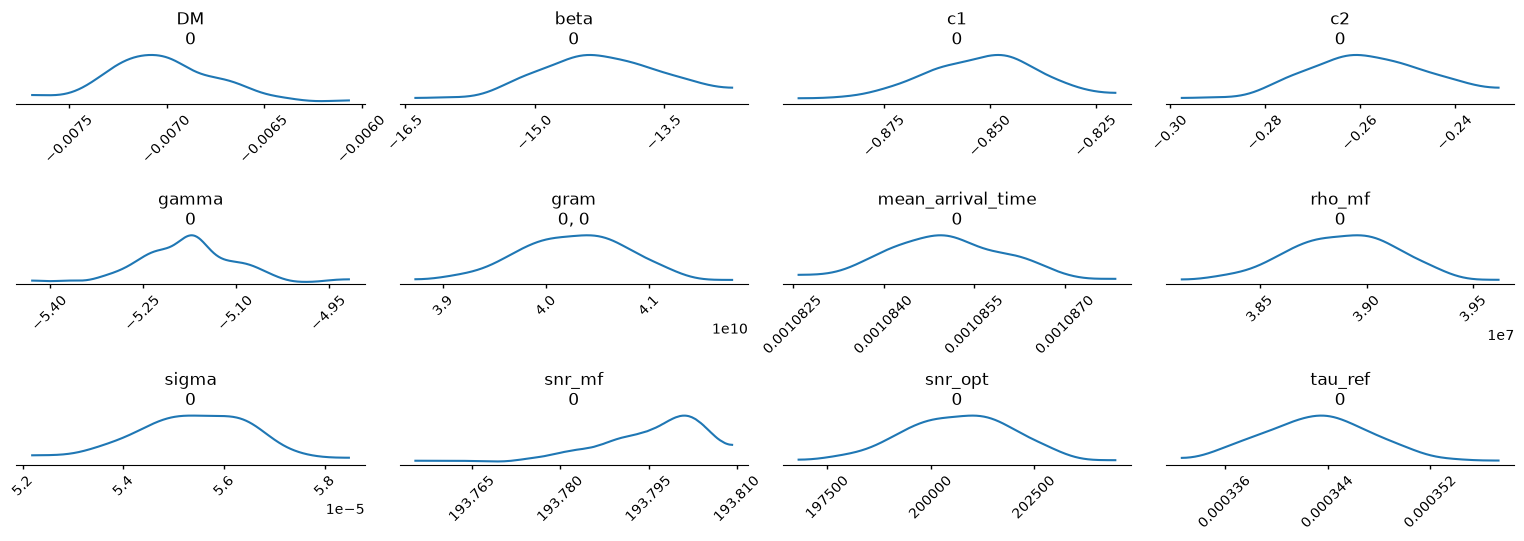

In [14]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw() 

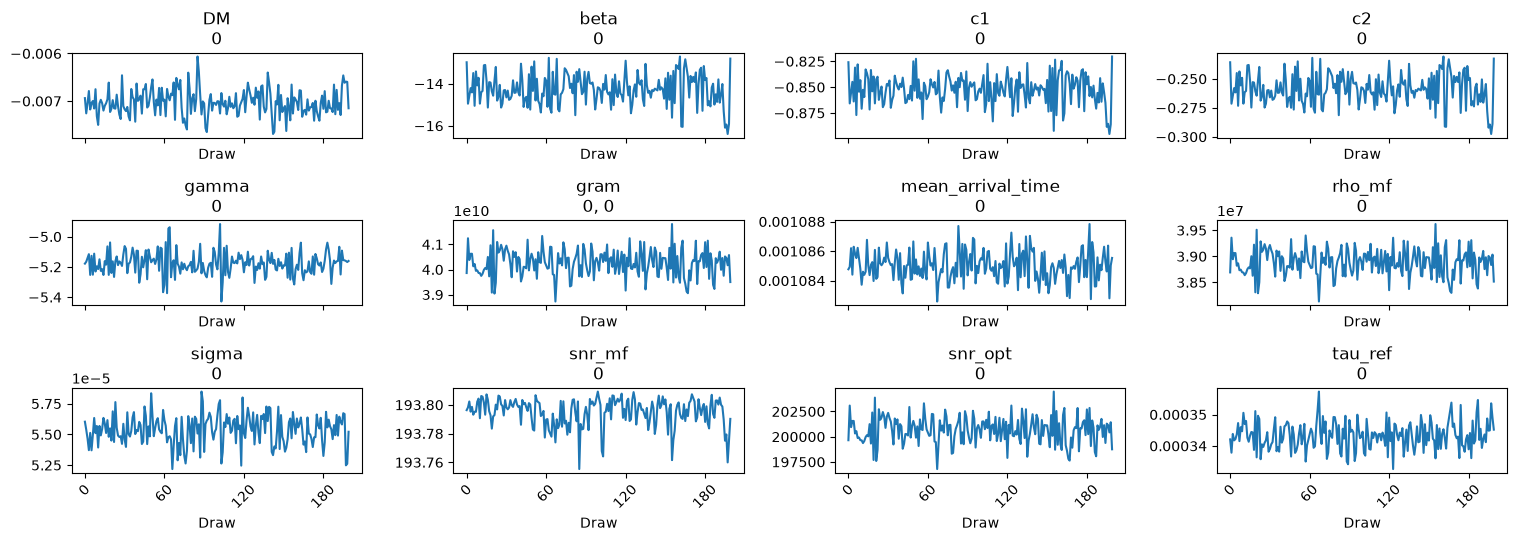

In [15]:
azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [16]:
# -------------------------------------------------------------------
# 5. Reconstruct Fluences
# -------------------------------------------------------------------

# fluences = draw_fluences_halfnormal_nooverlap_gaussmarg(
#     snr_opt=samples["snr_opt"],
#     snr_mf=samples["snr_mf"],
#     s_opt=s_opt,
#     key=key_fluences,
# )

samples = dict(mcmc.get_samples())          # flattened, (n_draws, n_pulses) per parameter
inv_noise_var = 1.0 / burst.sigma_noise_fd ** 2

# Half-normal no-overlap: every draw is valid
fluences = draw_fluences_halfnormal_nooverlap_gaussmarg(
    samples["snr_opt"], samples["snr_mf"], s_opt, key_fluences)

# Full-normal instead: draws with a negative fluence are rejected, and the mask applies to everything
# fluences, accept = draw_fluences_fullnormal_gaussmarg(samples["gram"], samples["rho_mf"], s_opt, key_fluences)
# samples = {k: v[accept] for k, v in samples.items()}; fluences = fluences[accept]

samples["A"] = fluences
samples["wraparound_ratio"] = wraparound_ratio_posthoc(
    samples, fluences, single_pulse_fn, inv_noise_var)

Plotting for Posterior Draw #189


/tmp/ipykernel_3850678/1393557241.py:117: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


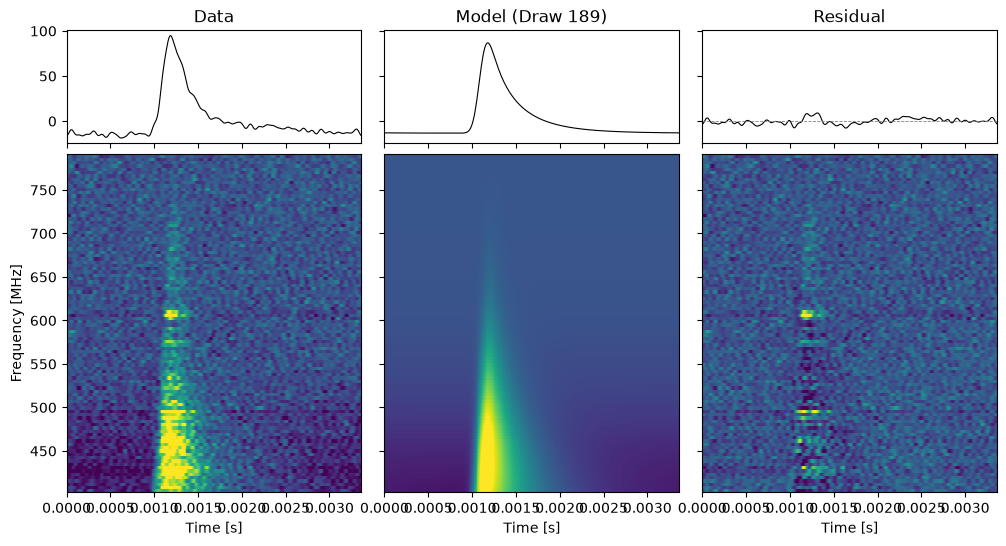

In [17]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Evaluate Forward Model
# -------------------------------------------------------------------
# samples = mcmc.get_samples()
num_draws = len(next(iter(samples.values())))

# Pick a draw index using JAX random
key = jax.random.PRNGKey(0)
draw_idx = int(jax.random.randint(key, shape=(), minval=0, maxval=num_draws))
print(f"Plotting for Posterior Draw #{draw_idx}")

# Extract parameters for the chosen draw directly as JAX scalars
test_params = {
    "mean_arrival_time": samples["mean_arrival_time"][draw_idx],
    "sigma": samples["sigma"][draw_idx],
    "DM": samples["DM"][draw_idx],
    "tau_ref": samples["tau_ref"][draw_idx],
    "c1": samples["c1"][draw_idx],
    "c2": samples["c2"][draw_idx],
}
A_scale = fluences[draw_idx]

# Extract amplitude scale from posterior ('gram' or fallback to default)
# A_scale = (
#     samples["gram"][draw_idx] if "gram" in samples else fluences[draw_idx]
# )

# Evaluate model in Fourier domain and transform to Time Domain
# The data and model now live on the truncated Fourier axis, so they must be placed back at
# their original bin indices before inverting; irfft(n=Nseg) on the truncated array would
# reinterpret bin k as frequency k/(Nseg dt), which is not where it came from.
Nseg = burst.n_time
dt=burst.dt
data_reshaped_FFT = burst.data_fd
n_full = Nseg // 2 + 1
pad = lambda X: jnp.zeros((X.shape[0], n_full), X.dtype).at[:, 1:1 + X.shape[-1]].set(X)

M_FD = single_pulse_fn(test_params) * A_scale
M_TD = (1.0 / dt) * jnp.fft.irfft(pad(M_FD), n=Nseg, axis=-1)
data_TD = (1.0 / dt) * jnp.fft.irfft(pad(data_reshaped_FFT), n=Nseg, axis=-1)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = burst.times
freq_plot = jnp.squeeze(burst.freq_channels)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Shared robust color limits using jnp
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_resid.set_title("Residual")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

Max Data abs : 39.16236
Max Model abs: 34.716522
whitened residual sd: 1.321  (expect 1)


/tmp/ipykernel_3850678/785051423.py:103: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


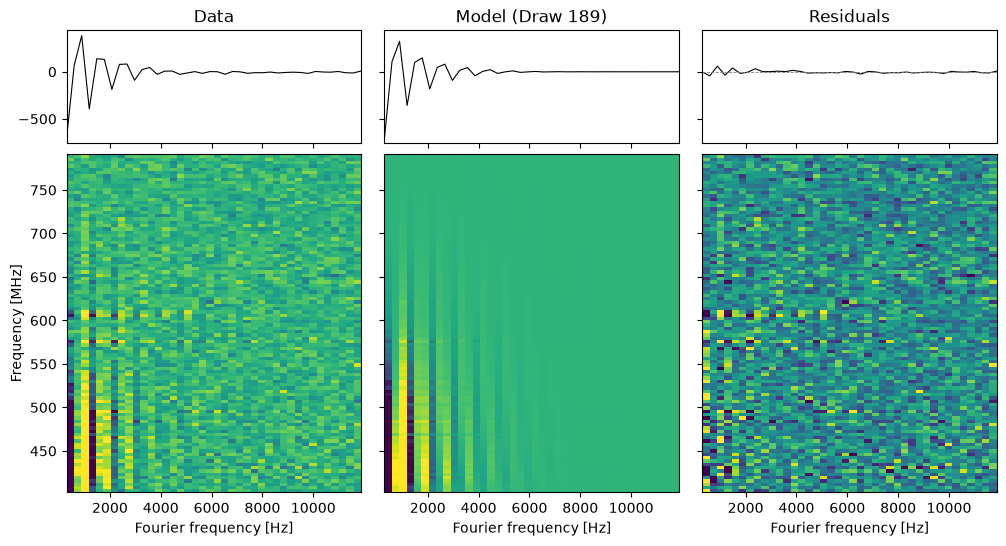

In [18]:
# -------------------------------------------------------------------
# 1. Forward model evaluation, Fourier domain
# -------------------------------------------------------------------
M_FD = single_pulse_fn(test_params) * A_scale

# data_reshaped_FFT and the model already live on the truncated Fourier axis, which is exactly
# the set of bins the likelihood uses, so nothing needs slicing here.
sigma_bins = jnp.broadcast_to(burst.sigma_noise_fd, data_reshaped_FFT.shape)

# Whitened, so all three panels are in units of sigma and the residual should be N(0, 1) noise
data_FD_plot = (data_reshaped_FFT / sigma_bins).real
model_FD_plot = (M_FD / sigma_bins).real
resid_FD_plot = data_FD_plot - model_FD_plot

fourier_freqs = burst.fourier_freqs
fourier_plot = jnp.asarray(fourier_freqs).reshape(-1)
freq_plot = jnp.squeeze(burst.freq_channels)

print("Max Data abs :", jnp.max(jnp.abs(data_FD_plot)))
print("Max Model abs:", jnp.max(jnp.abs(model_FD_plot)))
print(f"whitened residual sd: {float(jnp.std(resid_FD_plot)):.3f}  (expect 1)")

# -------------------------------------------------------------------
# 2. Channel-summed spectra
# -------------------------------------------------------------------
data_ts = jnp.nansum(data_FD_plot, axis=0)
model_ts = jnp.nansum(model_FD_plot, axis=0)
resid_ts = data_ts - model_ts

# Data & Model limits
vmin, vmax = jnp.nanpercentile(data_FD_plot, jnp.array([1.0, 99.0]))

# Independent zero-centered limits for Residuals
vmax_res = jnp.nanpercentile(jnp.abs(resid_FD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: channel-summed spectra ---
ax_ts_data.plot(fourier_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(fourier_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(fourier_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_FD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_FD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_FD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_data.set_title("Data")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Fourier frequency [Hz]")
ax_wf_model.set_xlabel("Fourier frequency [Hz]")
ax_wf_resid.set_xlabel("Fourier frequency [Hz]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

## Unmarg orthog SED

In [19]:
# -------------------------------------------------------------------
# 1. Data Conditioning
# -------------------------------------------------------------------
# prepare_burst averages the frequency channels, transforms to the Fourier domain, truncates the
# Fourier axis, and builds the orthogonal spectral basis. Everything the model and likelihood
# need comes back in `burst`, so neither has to know how the conditioning was done.
burst = prepare_burst(
    path="/mnt/home/hsiegel/FRBayes/data/event_22154974_BB.npz",
    n_avg=8,                # frequency channels averaged per block
    fd_downsample=4,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

# -------------------------------------------------------------------
# 2. Model Closure Setup
# -------------------------------------------------------------------
constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
}

# Orthogonal spectral basis: sample c1, c2 rather than gamma, beta. Over a factor-of-two band
# x = ln(nu/nu_r) and x^2 are nearly parallel, which makes gamma and beta strongly degenerate;
# P1 and P2 are orthogonal in the metric set by the per-channel weights, and orthogonal to the
# constant, which also decouples them from the fluence.
#
# setup_model also builds the same model on [f1/2, f1], f1 = 1 / W_seg, and attaches it as
# single_pulse_fn.lowfreq_diagnostic, for the wraparound ratio. No separate closure is needed.
single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

# containment = dict(
#     n_sigma= 3.0,
#     n_tau = 1.0,
#     extent_max=0.5 * burst.n_time * burst.dt,                        # xi = 0.5, shared with D_max
#     sigma_min=1.0 / (2 * jnp.pi * float(burst.fourier_freqs[-1])),    # narrowest resolvable width
#     bot_over_ref=float(burst.freq_channels[0][0]) / burst.freq_channels_ref,
# )

# Wraparound penalty during sampling. In this (unmarginalized) likelihood the ratio is recorded
# as 'wraparound_ratio' on every draw regardless, exactly, since A is sampled; containment_FD
# only decides whether it is also penalized. To switch the penalty on, use the dict below.
containment_FD = None
# containment_FD = dict(
#     ratio_min=0.9,   # how much of the envelope must survive at f1
#     K=100.0,         # penalty at ratio = 0, in nats
#     w=0.01,          # sharpness of the transition
# )

# -------------------------------------------------------------------
# 3. Priors & NUTS Sampling
# -------------------------------------------------------------------

width_prior = width_prior_bounds(burst, toa=1.15e-3)
spectral_prior = spectral_coeff_bounds(burst.spectral_coeff_map, [-10,200],[-200,10])
DM_prior = dispersion_prior_bounds(burst,single_pulse_fn)
s_opt = 100

priors = {
    # "mean_arrival_time": dist.Uniform(0.00115 - 5*2e-4, 0.00115 + 7*2e-4),   # (s, relative to segment start)
    "mean_arrival_time": dist.Uniform(0, burst.times[-1]),   # (s, relative to segment start)

    # "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
    "DM": dist.Uniform(DM_prior["DM"][0], DM_prior["DM"][1]),                  # residual DM (pc cm^-3)
    # "tau_ref": dist.Uniform(1e-5, 2e-3),            # scattering timescale at nu_r (s)

    # Orthogonal basis coefficients, O(1) by construction (unit weighted RMS basis). These are
    # specific to this burst's basis and are not comparable between bursts; gamma and beta are
    # recorded as deterministic sites via spectral_coeff_map and are what should be reported.
    "c1": dist.Uniform(spectral_prior["c1_min"], spectral_prior["c1_max"]),                  # linear basis coefficient
    "c2": dist.Uniform(spectral_prior["c2_min"], spectral_prior["c2_max"]),                  # quadratic basis coefficient
     # "A": dist.Uniform(1e-5, 1e-2),
    #"A_snr": dist.Uniform(0,250),
    "A_snr": dist.HalfNormal(s_opt),
    "sigma": dist.Uniform(width_prior["sigma_min"],width_prior["sigma_max"]),   # floor from the Fourier truncation
    "tau_ref": dist.Uniform(width_prior["tau_ref_min"],width_prior["tau_ref_max"]),
}

n_pulses = 1

num_warmup = 1000
num_samples = 200
num_chains = 1

# Fixed master key seed for reproducible sampling across runs
key_sampler, key_fluences = jax.random.split(jax.random.PRNGKey(3))


#initialization of sampler
W = burst.n_time * burst.dt
init = init_to_value(values={
    "sigma": jnp.array([width_prior["sigma_max"]*0.9]),
    #"sigma": jnp.array([(width_prior["sigma_min"]+width_prior["sigma_max"])/2]),
    "tau_ref": jnp.array([5*burst.dt]),
    "mean_arrival_time": jnp.array([0.5 * W]),
    "DM": jnp.array([0]),
    "c1": jnp.array([0]),
    "c2": jnp.array([0])
})


# kernel = NUTS(FD_gaussianlikelihood, dense_mass=True)
kernel = NUTS(FD_gaussianlikelihood, dense_mass=True, init_strategy=init)

mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains,
            chain_method="parallel")

mcmc.run(
    key_sampler,
    data_fd=burst.data_fd,
    sigma_noise_fd=burst.sigma_noise_fd,
    n_pulses=n_pulses,
    priors=priors,
    single_pulse_fn=single_pulse_fn,
    spectral_coeff_map=burst.spectral_coeff_map,
    containment_FD=containment_FD,
    extra_fields=("num_steps", "accept_prob", "diverging", "potential_energy")
)

# -------------------------------------------------------------------
# 4. Extract Posteriors
# -------------------------------------------------------------------
# A is sampled directly here (as A_snr, with the fluence A = A_snr / SNR_opt recorded as the 'A'
# site), so there is no conditional fluence draw. The wraparound ratio is recorded in the model
# on every draw, exactly, so there is no post-hoc step either.
samples = dict(mcmc.get_samples())
extra = mcmc.get_extra_fields()

print(f"wraparound_ratio: min {float(samples['wraparound_ratio'].min()):.4f}, "
      f"median {float(jnp.median(samples['wraparound_ratio'])):.4f}")

mcmc_data = az.from_dict(
    {"posterior": {k: np.asarray(v)[None, ...] for k, v in samples.items()}}
)

820 good channels -> 102 blocks of 8 (4 dropped); block span median 3.125 MHz, max 4.688 MHz
noise estimated from 65 of 329 time bins (first 20% of the segment)
Fourier truncation: keeping 40 of 165 bins (up to 11.9 kHz of 48.7 kHz)
weighted mean frequency 460.7 MHz, reference frequency 453.2 MHz
prior being set with bounds:
sigma_min = 1.3404665608610986e-05 
sigma_max = 0.00038333333333333334 
tau_ref_min = 0.0 
tau_ref_max = 0.0013766223072632156
prior being set with bounds:
c1_min = -5.25784 
c1_max = 21.606956 
c2_min = -3.6313496 
c2_max = 0.18156748
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


  0%|          | 0/1200 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 1200/1200 [00:06<00:00, 183.45it/s, 15 steps of size 3.50e-01. acc. prob=0.92]

wraparound_ratio: min 0.8465, median 0.8536


In [20]:
# -------------------------------------------------------------------
# 4. Extract Posteriors
# -------------------------------------------------------------------
samples = mcmc.get_samples()
extra = mcmc.get_extra_fields()
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


In [22]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.001,0.000,0.001,0.001,166.397,135.519,NaN,0.000,0.000
A_snr[0],193.677,1.017,192.178,195.233,232.913,130.887,NaN,0.072,0.073
DM[0],-0.007,0.000,-0.007,-0.007,132.946,112.939,NaN,0.000,0.000
beta[0],-14.362,0.747,-15.592,-13.259,169.597,121.854,NaN,0.057,0.056
c1[0],-0.854,0.013,-0.875,-0.835,180.735,126.033,NaN,0.001,0.001
c2[0],-0.261,0.014,-0.283,-0.241,169.597,121.854,NaN,0.001,0.001
gamma[0],-5.172,0.071,-5.283,-5.045,280.870,138.277,NaN,0.004,0.005
mean_arrival_time[0],0.001,0.000,0.001,0.001,186.040,192.944,NaN,0.000,0.000
sigma[0],0.000,0.000,0.000,0.000,144.840,115.179,NaN,0.000,0.000
snr_opt[0],200764.000,1389.204,198420.004,202769.069,200.308,189.671,NaN,98.988,109.830


In [23]:
ex = mcmc.get_extra_fields()
ns = jnp.array(ex["num_steps"])                    # (chain, draw) with num_chains > 1
n_chains = ns.shape[0] if ns.ndim > 1 else 1
ns = ns.reshape(n_chains, -1)
acc = jnp.array(ex["accept_prob"]).reshape(n_chains, -1)
div = jnp.array(ex["diverging"]).reshape(n_chains, -1)
pe = jnp.array(ex["potential_energy"]).reshape(n_chains, -1)
step = jnp.atleast_1d(mcmc.last_state.adapt_state.step_size)

for c in range(n_chains):
    print(f"chain {c}: grads/sample mean {ns[c].mean():5.1f} max {ns[c].max():4d} | "
          f"max depth {100*jnp.mean(ns[c] >= 2**10 - 1):4.1f}% | "
          f"accept {acc[c].mean():.3f} | div {int(div[c].sum())}/{ns.shape[1]} | "
          f"step {float(step[c % step.size]):.3e} | "
          f"U mean {pe[c].mean():9.1f} sd {pe[c].std():.2f}")

chain 0: grads/sample mean  10.3 max   15 | max depth  0.0% | accept 0.922 | div 0/200 | step 3.500e-01 | U mean    7131.1 sd 1.65


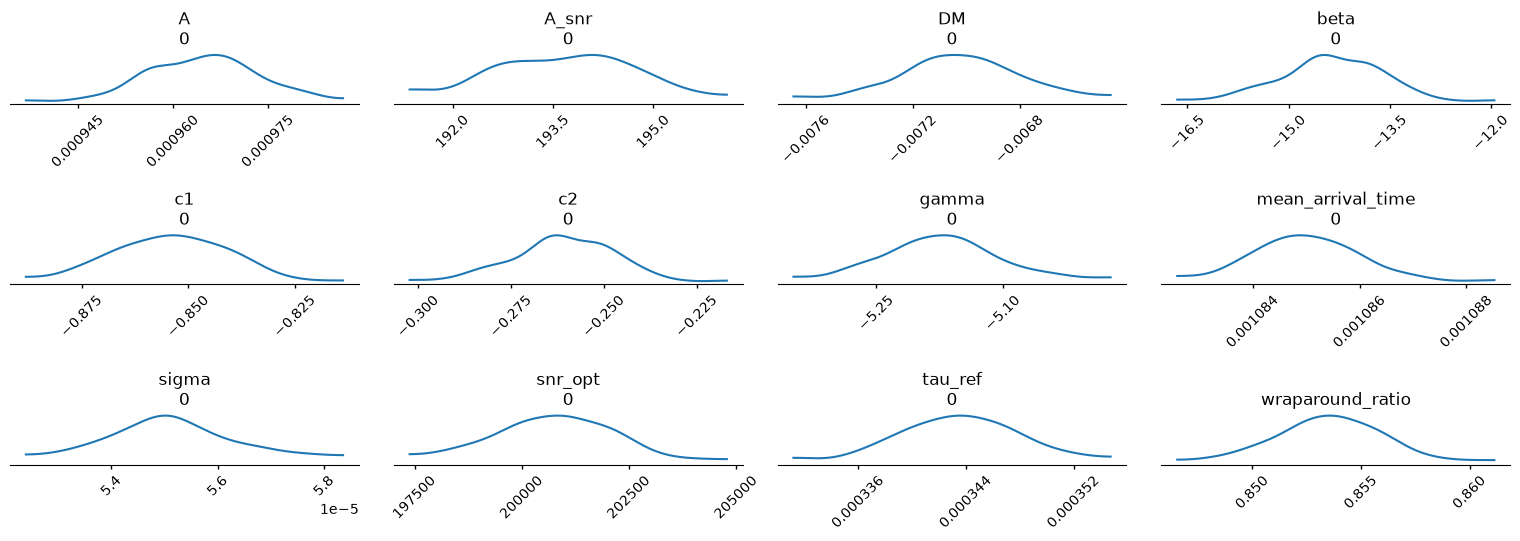

In [24]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw() 

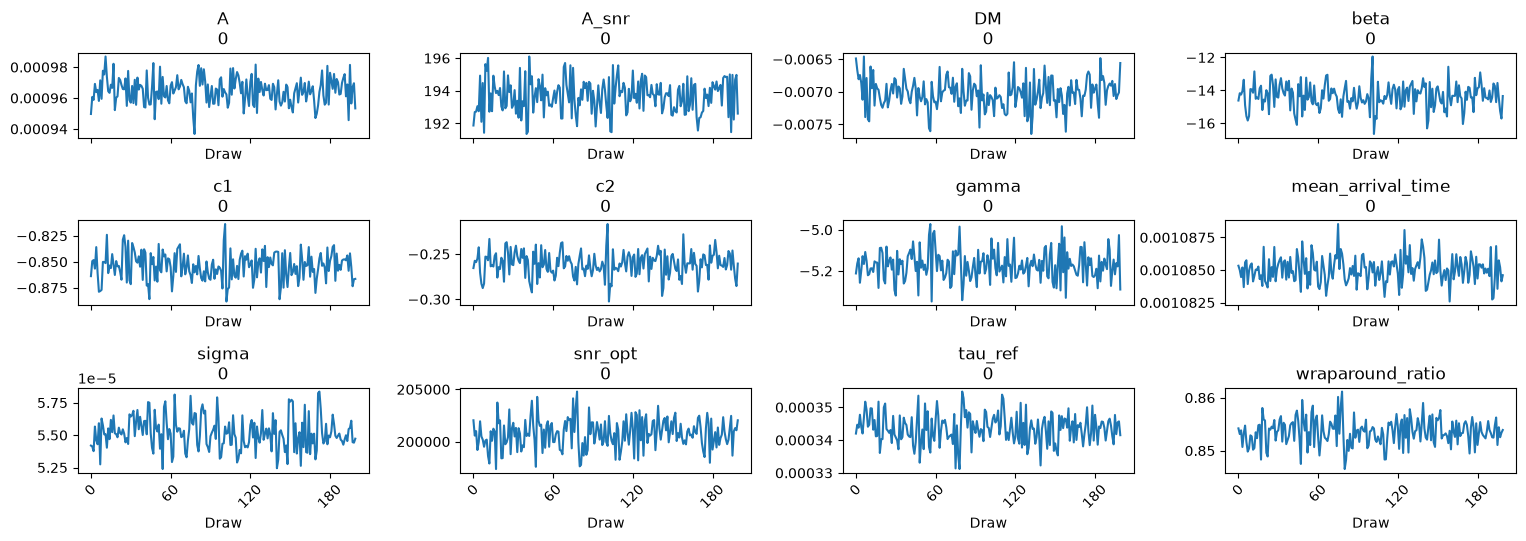

In [25]:
azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Plotting for Posterior Draw #196


/tmp/ipykernel_3850678/2219313781.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


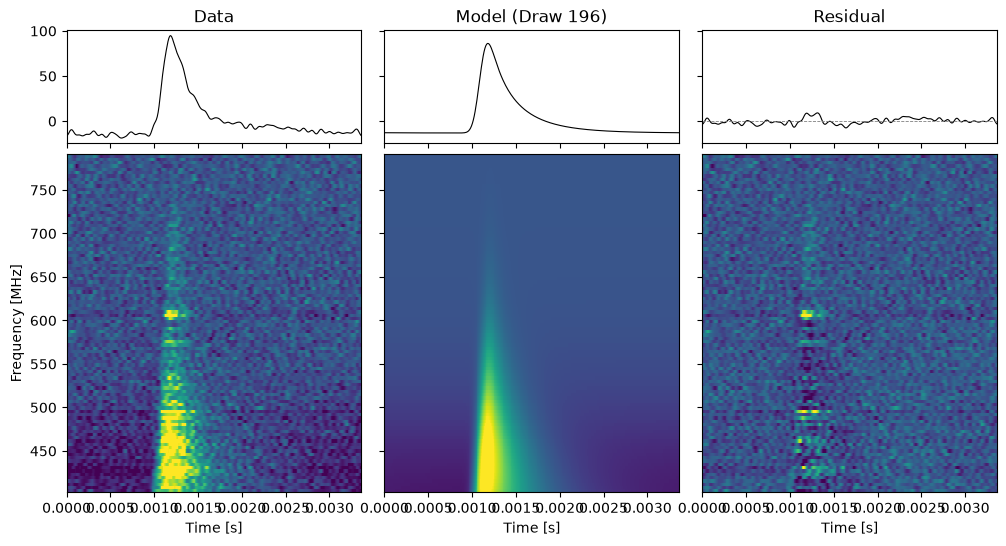

In [26]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Evaluate Forward Model
# -------------------------------------------------------------------
# samples = mcmc.get_samples()
num_draws = len(next(iter(samples.values())))

# Pick a draw index using JAX random
key = jax.random.PRNGKey(1)
draw_idx = int(jax.random.randint(key, shape=(), minval=0, maxval=num_draws))
print(f"Plotting for Posterior Draw #{draw_idx}")

# Extract parameters for the chosen draw directly as JAX scalars
test_params = {
    "mean_arrival_time": samples["mean_arrival_time"][draw_idx],
    "sigma": samples["sigma"][draw_idx],
    "DM": samples["DM"][draw_idx],
    "tau_ref": samples["tau_ref"][draw_idx],
    "c1": samples["c1"][draw_idx],
    "c2": samples["c2"][draw_idx],
    "A": samples["A"][draw_idx]
}
# test_params={'sigma': width_prior["sigma_max"]*0.9,#0.00019837, 
#              'tau_ref': 5*burst.dt, 
#              'mean_arrival_time':0.00168448,
#              'DM': 0, 
#              'c1': 0,
#              'c2': 0,
#              "A": samples["A"][draw_idx]}


# Extract amplitude scale from posterior ('gram' or fallback to default)
# A_scale = (
#     samples["gram"][draw_idx] if "gram" in samples else fluences[draw_idx]
# )

# Evaluate model in Fourier domain and transform to Time Domain
# The data and model now live on the truncated Fourier axis, so they must be placed back at
# their original bin indices before inverting; irfft(n=Nseg) on the truncated array would
# reinterpret bin k as frequency k/(Nseg dt), which is not where it came from.
Nseg = burst.n_time
dt=burst.dt
data_reshaped_FFT = burst.data_fd
n_full = Nseg // 2 + 1
pad = lambda X: jnp.zeros((X.shape[0], n_full), X.dtype).at[:, 1:1 + X.shape[-1]].set(X)

M_FD = single_pulse_fn(test_params)
M_TD = (1.0 / dt) * jnp.fft.irfft(pad(M_FD), n=Nseg, axis=-1)
data_TD = (1.0 / dt) * jnp.fft.irfft(pad(data_reshaped_FFT), n=Nseg, axis=-1)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = burst.times
freq_plot = jnp.squeeze(burst.freq_channels)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Shared robust color limits using jnp
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_resid.set_title("Residual")
# ax_ts_data.axvline(0.00115 - 5*2e-4)
# ax_ts_data.axvline(0.00115 + 7*2e-4)

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

Max Data abs : 39.16236
Max Model abs: 34.29291
whitened residual sd: 1.323  (expect 1)


/tmp/ipykernel_3850678/1186744876.py:103: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


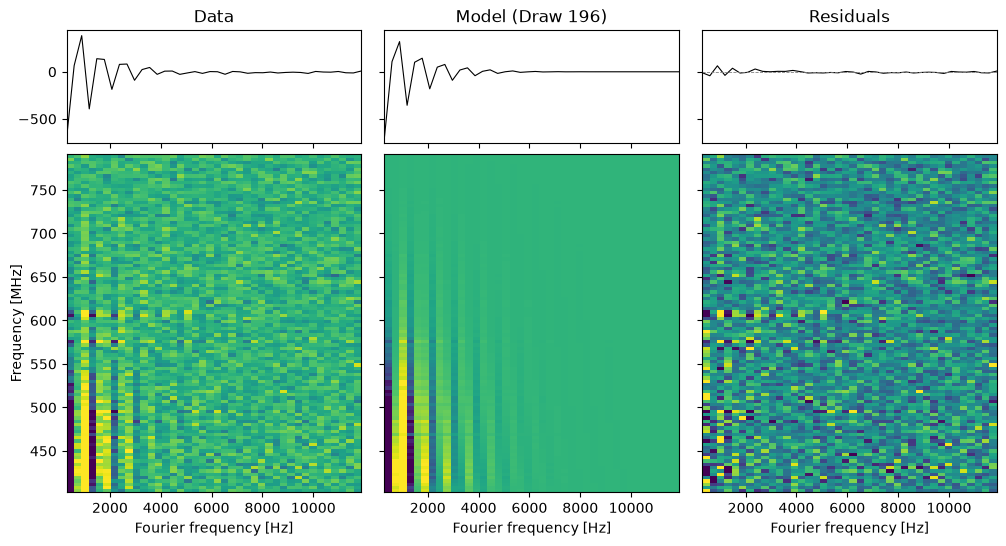

In [27]:
# -------------------------------------------------------------------
# 1. Forward model evaluation, Fourier domain
# -------------------------------------------------------------------
M_FD = single_pulse_fn(test_params)

# data_reshaped_FFT and the model already live on the truncated Fourier axis, which is exactly
# the set of bins the likelihood uses, so nothing needs slicing here.
sigma_bins = jnp.broadcast_to(burst.sigma_noise_fd, data_reshaped_FFT.shape)

# Whitened, so all three panels are in units of sigma and the residual should be N(0, 1) noise
data_FD_plot = (data_reshaped_FFT / sigma_bins).real
model_FD_plot = (M_FD / sigma_bins).real
resid_FD_plot = data_FD_plot - model_FD_plot

fourier_freqs = burst.fourier_freqs
fourier_plot = jnp.asarray(fourier_freqs).reshape(-1)
freq_plot = jnp.squeeze(burst.freq_channels)

print("Max Data abs :", jnp.max(jnp.abs(data_FD_plot)))
print("Max Model abs:", jnp.max(jnp.abs(model_FD_plot)))
print(f"whitened residual sd: {float(jnp.std(resid_FD_plot)):.3f}  (expect 1)")

# -------------------------------------------------------------------
# 2. Channel-summed spectra
# -------------------------------------------------------------------
data_ts = jnp.nansum(data_FD_plot, axis=0)
model_ts = jnp.nansum(model_FD_plot, axis=0)
resid_ts = data_ts - model_ts

# Data & Model limits
vmin, vmax = jnp.nanpercentile(data_FD_plot, jnp.array([1.0, 99.0]))

# Independent zero-centered limits for Residuals
vmax_res = jnp.nanpercentile(jnp.abs(resid_FD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: channel-summed spectra ---
ax_ts_data.plot(fourier_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(fourier_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(fourier_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_FD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_FD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_FD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_data.set_title("Data")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Fourier frequency [Hz]")
ax_wf_model.set_xlabel("Fourier frequency [Hz]")
ax_wf_resid.set_xlabel("Fourier frequency [Hz]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()